# QPM 2026-2027 — Notebook 00: The Python toolkit for Quantitative Portfolio Management

**EDHEC · Quantitative Portfolio Management (Prof. R. Uppal) · Personal study notebook**

This notebook is a refresher on the Python you need for the course. It is **not** an introduction to Python: it covers the commands that keep coming back in the slides and the assignments.

**Why this matters:** the final exam (85% of the grade) is **handwritten**: you must write Python code on paper, without a computer. So for each block we highlight the *few lines you must be able to write from memory* (look for ✍️ **Exam-ready**).

**Contents**
1. NumPy: vectors, matrices and the portfolio formulas
2. Random numbers and simulation
3. pandas: DataFrames, tidy vs. wide data
4. Returns with pandas: `pct_change`, `groupby`, `shift`
5. Method chaining with `assign` and `lambda` (the Tidy Finance style)
6. Annualising, rolling windows, resampling
7. Exercises (with hidden solutions)

Run the cells in order (in Colab: *Runtime → Run all*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 4)
np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


## 1. NumPy: vectors, matrices and the portfolio formulas

The key expression of the course is

$$ w = \frac{1}{\gamma}\, V[R]^{-1}\,\big(E[R] - R_f \mathbf 1_N\big). $$

To compute it you need four NumPy objects: a vector of expected returns, a covariance matrix, a vector of ones, and a linear solver.

In [2]:
# A 3-asset example (annual numbers)
mu = np.array([0.08, 0.10, 0.06])          # E[R] - 1, net expected returns
vol = np.array([0.15, 0.20, 0.10])         # volatilities
corr = np.array([[1.0, 0.3, 0.2],
                 [0.3, 1.0, 0.4],
                 [0.2, 0.4, 1.0]])         # correlation matrix

# Covariance matrix: V = diag(vol) @ corr @ diag(vol)
V = np.diag(vol) @ corr @ np.diag(vol)
print("Covariance matrix V:\n", V)

# Same thing with "outer product": V_nm = vol_n * vol_m * corr_nm
V2 = np.outer(vol, vol) * corr
print("Same matrix?", np.allclose(V, V2))

Covariance matrix V:
 [[0.0225 0.009  0.003 ]
 [0.009  0.04   0.008 ]
 [0.003  0.008  0.01  ]]
Same matrix? True


### `@`, `.T`, `np.ones`, `np.eye`

* `A @ B` is matrix multiplication (`*` is element-by-element!).
* `x.T` is the transpose. For a 1-D NumPy array `x.T` does nothing: NumPy treats 1-D arrays as vectors, and `w @ mu` is already the inner product $w^\top \mu$.
* `np.ones(N)` is $\mathbf 1_N$, `np.eye(N)` is the identity matrix $I_N$.

In [3]:
w = np.array([0.5, 0.3, 0.2])
ones = np.ones(3)

print("Sum of weights  w'1     =", w @ ones)
print("Portfolio mean  w'mu    =", w @ mu)
print("Portfolio var   w'Vw    =", w @ V @ w)
print("Portfolio vol   sqrt    =", np.sqrt(w @ V @ w))
print("Element-wise w*mu       =", w * mu, "  <- NOT the portfolio mean")

Sum of weights  w'1     = 1.0
Portfolio mean  w'mu    = 0.082
Portfolio var   w'Vw    = 0.013885
Portfolio vol   sqrt    = 0.11783462988442744
Element-wise w*mu       = [0.04  0.03  0.012]   <- NOT the portfolio mean


### Solve, don't invert

$V^{-1}x$ can be computed as `np.linalg.inv(V) @ x`, but `np.linalg.solve(V, x)` is faster and **numerically more stable** (it never forms the inverse). The slides always use `solve`.

In [4]:
rf, gamma = 0.02, 3

# Mean-variance weights
w_mv = np.linalg.solve(V, mu - rf * ones) / gamma
w_mv_inv = np.linalg.inv(V) @ (mu - rf * ones) / gamma
print("MV weights (solve):", w_mv)
print("MV weights (inv)  :", w_mv_inv)
print("Weight in risk-free asset: 1 - w'1 =", 1 - w_mv.sum())

# Global minimum-variance (GMV) weights: V^{-1} 1 / (1' V^{-1} 1)
w_gmv = np.linalg.solve(V, ones)
w_gmv = w_gmv / w_gmv.sum()
print("GMV weights:", w_gmv, " sum =", w_gmv.sum())

MV weights (solve): [0.6332 0.3518 0.8619]
MV weights (inv)  : [0.6332 0.3518 0.8619]
Weight in risk-free asset: 1 - w'1 = -0.8469656992084431
GMV weights: [ 0.2652 -0.0036  0.7384]  sum = 1.0


✍️ **Exam-ready (learn by heart)**
```python
ones = np.ones(len(mu))
w_mv  = np.linalg.solve(V, mu - rf * ones) / gamma      # mean-variance
w_gmv = np.linalg.solve(V, ones); w_gmv = w_gmv / w_gmv.sum()   # GMV
port_mean = w @ mu
port_vol  = np.sqrt(w @ V @ w)
```

**Check yourself:** the first-order condition of $\max_w\, w^\top(\mu - r_f\mathbf 1) - \tfrac{\gamma}{2} w^\top V w$ is $\mu - r_f \mathbf 1 = \gamma V w$. Let's verify it numerically.

In [5]:
lhs = mu - rf * ones
rhs = gamma * V @ w_mv
print("FOC satisfied?", np.allclose(lhs, rhs))

FOC satisfied? True


### Eigenvalues and the condition number

The **condition number** $\kappa(V)=\lambda_{\max}/\lambda_{\min}$ measures how close $V$ is to being singular. A large $\kappa$ means $V^{-1}$ amplifies errors, which is the central problem of Chapter 1.

In [6]:
eigval, eigvec = np.linalg.eigh(V)     # eigh: for symmetric matrices
print("Eigenvalues:", eigval)
print("Condition number (by hand):", eigval.max() / eigval.min())
print("Condition number (numpy)  :", np.linalg.cond(V))

Eigenvalues: [0.008  0.0187 0.0458]
Condition number (by hand): 5.761530024875298
Condition number (numpy)  : 5.7615300248753005


## 2. Random numbers and simulation

All Python exercises in the slides use **simulated data**: we know the *true* parameters, so we can check how far the estimates are from the truth.

* `rng = np.random.default_rng(seed)` creates a reproducible random generator.
* `rng.normal(mean, sd, size=(T, N))` gives a $T\times N$ matrix (rows = dates, columns = assets).
* `rng.multivariate_normal(mean_vector, V, size=T)` draws correlated returns.

In [7]:
rng = np.random.default_rng(42)
T = 120                                       # 10 years of monthly data
R = rng.multivariate_normal(mu / 12, V / 12, size=T)   # monthly returns
print("Shape (T, N):", R.shape)

mu_hat = R.mean(axis=0) * 12                  # axis=0: average over dates (rows)
V_hat = np.cov(R, rowvar=False) * 12          # rowvar=False: columns are variables
print("True mu     :", mu)
print("Estimated mu:", mu_hat)
print("True vols     :", vol)
print("Estimated vols:", np.sqrt(np.diag(V_hat)))

Shape (T, N): (120, 3)
True mu     : [0.08 0.1  0.06]
Estimated mu: [0.068  0.0889 0.0444]
True vols     : [0.15 0.2  0.1 ]
Estimated vols: [0.1443 0.1917 0.0906]


👉 Notice: with 10 years of data the **volatilities** are estimated quite well, the **means** much worse. This is exactly the message of Chapter 1 (Python exercise 3).

### `axis`, `reshape`, `cumprod`

* `axis=0` operates **down the rows** (across dates) → one number per asset.
* `axis=1` operates **across the columns** (across assets) → one number per date.
* `reshape` turns daily data into blocks, e.g. 2520 days → 120 months × 21 days.
* `np.cumprod(1 + r)` builds a price/wealth path from returns.

daily: (2520,) -> monthly: (120,)


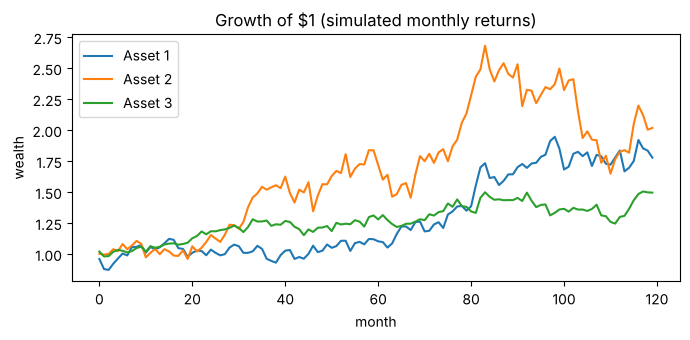

In [8]:
daily = rng.normal(0.0003, 0.01, size=2520)          # 10 years of daily log returns
monthly = daily.reshape(120, 21).sum(axis=1)         # log returns add up over time
print("daily:", daily.shape, "-> monthly:", monthly.shape)

wealth = np.cumprod(1 + R, axis=0)                   # wealth of $1 in each asset
plt.figure(figsize=(7, 3.5))
plt.plot(wealth)
plt.title("Growth of $1 (simulated monthly returns)")
plt.xlabel("month"); plt.ylabel("wealth"); plt.legend(["Asset 1", "Asset 2", "Asset 3"])
plt.tight_layout(); plt.show()

## 3. pandas: DataFrames, tidy vs. wide data

The course follows the **tidy data** principles of Tidy Finance:
1. every column is a variable;
2. every row is an observation;
3. every cell is a single value.

| Format | Shape | Use it for |
|---|---|---|
| **tidy / long** | one row per *(date, asset)* | storing, merging, `groupby` |
| **wide** | one row per date, one column per asset | matrix algebra: `cov`, `corr`, $V^{-1}$ |

Rule from the slides: **store tidy, pivot to wide only for matrix calculations.**

In [9]:
dates = pd.date_range("2024-01-31", periods=6, freq="ME")   # month-end dates
prices_wide = pd.DataFrame(
    {"AAA": [100, 102, 101, 105, 107, 106],
     "BBB": [50, 49, 51, 52, 50, 53]},
    index=pd.Index(dates, name="date"))
prices_wide

,AAA,BBB
date,,
2024-01-31,100,50
2024-02-29,102,49
2024-03-31,101,51
2024-04-30,105,52
2024-05-31,107,50
2024-06-30,106,53


In [10]:
# wide -> long: melt
prices = (prices_wide
          .reset_index()                                   # date becomes a column
          .melt(id_vars="date", var_name="symbol", value_name="price")
          .sort_values(["symbol", "date"])
          .reset_index(drop=True))
prices

,date,symbol,price
0,2024-01-31,AAA,100
1,2024-02-29,AAA,102
2,2024-03-31,AAA,101
3,2024-04-30,AAA,105
4,2024-05-31,AAA,107
5,2024-06-30,AAA,106
6,2024-01-31,BBB,50
7,2024-02-29,BBB,49
8,2024-03-31,BBB,51
9,2024-04-30,BBB,52


In [11]:
# long -> wide: pivot
back_to_wide = prices.pivot(index="date", columns="symbol", values="price")
back_to_wide

symbol,AAA,BBB
date,,
2024-01-31,100,50
2024-02-29,102,49
2024-03-31,101,51
2024-04-30,105,52
2024-05-31,107,50
2024-06-30,106,53


## 4. Returns with pandas

**The classic mistake** (Python exercise 2 in the slides): calling `pct_change()` on a tidy column mixes different stocks. The first "return" of BBB is computed from the last price of AAA!

In [12]:
prices["ret_wrong"] = prices["price"].pct_change()
prices["ret"] = prices.groupby("symbol")["price"].pct_change()
prices

,date,symbol,price,ret_wrong,ret
0,2024-01-31,AAA,100,NaN,NaN
1,2024-02-29,AAA,102,0.0200,0.0200
2,2024-03-31,AAA,101,-0.0098,-0.0098
3,2024-04-30,AAA,105,0.0396,0.0396
4,2024-05-31,AAA,107,0.0190,0.0190
5,2024-06-30,AAA,106,-0.0093,-0.0093
6,2024-01-31,BBB,50,-0.5283,NaN
7,2024-02-29,BBB,49,-0.0200,-0.0200
8,2024-03-31,BBB,51,0.0408,0.0408
9,2024-04-30,BBB,52,0.0196,0.0196


Look at row 6: `ret_wrong` = 50/106 − 1 = −52.8%, which is meaningless. With `groupby("symbol")` the first return of each stock is correctly `NaN`.

✍️ **Exam-ready**
```python
df = df.sort_values(["symbol", "date"])
df["ret"] = df.groupby("symbol")["adjusted"].pct_change()
```

### Log returns and `shift`
* $\ln R_t = \ln P_t - \ln P_{t-1}$ → `np.log(p) - np.log(p.shift(1))`, or `np.log(1 + ret)`.
* `shift(1)` moves data **down** (yesterday's value on today's row): use it for *lagged* predictors.
* `shift(-1)` moves data **up** (tomorrow's value on today's row): use it for the *next-period* return you want to predict. In Welch–Goyal, `rp_div = (...).shift(-1)` lines up next month's return with this month's predictors, so there is no look-ahead bias.

In [13]:
aaa = prices.query("symbol == 'AAA'").copy()
aaa["log_ret"] = np.log(aaa["price"]) - np.log(aaa["price"].shift(1))
aaa["log_ret_check"] = np.log(1 + aaa["ret"])
aaa["next_ret"] = aaa["ret"].shift(-1)     # target for a predictive regression
aaa[["date", "price", "ret", "log_ret", "log_ret_check", "next_ret"]]

,date,price,ret,log_ret,log_ret_check,next_ret
0,2024-01-31,100,NaN,NaN,NaN,0.0200
1,2024-02-29,102,0.0200,0.0198,0.0198,-0.0098
2,2024-03-31,101,-0.0098,-0.0099,-0.0099,0.0396
3,2024-04-30,105,0.0396,0.0388,0.0388,0.0190
4,2024-05-31,107,0.0190,0.0189,0.0189,-0.0093
5,2024-06-30,106,-0.0093,-0.0094,-0.0094,NaN


## 5. Method chaining with `assign` and `lambda`

The slides (and Tidy Finance) write code as a **chain** of operations inside parentheses. Each line takes the DataFrame from the previous line.

* `.assign(new_col = lambda x: ...)`: `x` is the DataFrame *at that point of the chain*.
* `.rename(columns={...})`, `.get([...])` (select columns), `.query("...")` (filter rows), `.dropna()`.

In [14]:
returns = (prices
  .sort_values(["symbol", "date"])
  .assign(ret=lambda x: x.groupby("symbol")["price"].pct_change(),
          log_ret=lambda x: np.log(1 + x["ret"]))
  .get(["symbol", "date", "ret", "log_ret"])
  .dropna()
)
returns

,symbol,date,ret,log_ret
1,AAA,2024-02-29,0.0200,0.0198
2,AAA,2024-03-31,-0.0098,-0.0099
3,AAA,2024-04-30,0.0396,0.0388
4,AAA,2024-05-31,0.0190,0.0189
5,AAA,2024-06-30,-0.0093,-0.0094
7,BBB,2024-02-29,-0.0200,-0.0202
8,BBB,2024-03-31,0.0408,0.0400
9,BBB,2024-04-30,0.0196,0.0194
10,BBB,2024-05-31,-0.0385,-0.0392
11,BBB,2024-06-30,0.0600,0.0583


In [15]:
# Summary statistics per stock: groupby + agg
summary = (returns
  .groupby("symbol")["ret"]
  .agg(mean="mean", sd="std", n="count")
  .assign(mean_ann=lambda x: 12 * x["mean"],
          vol_ann=lambda x: np.sqrt(12) * x["sd"]))
summary

,mean,sd,n,mean_ann,vol_ann
symbol,,,,,
AAA,0.0119,0.0213,5,0.1428,0.0736
BBB,0.0124,0.0411,5,0.1487,0.1424


⚠️ **`ddof`:** pandas `.std()`, `.var()`, `.cov()` divide by $T-1$ (`ddof=1`); NumPy `np.std`, `np.var` divide by $T$ (`ddof=0`). The formulas in the slides divide by $T$. For large $T$ the difference is negligible, but your numbers will not match exactly if you mix the two.

In [16]:
x = np.array([1.0, 2.0, 3.0, 4.0])
print("np.var  (ddof=0):", np.var(x))
print("pd .var (ddof=1):", pd.Series(x).var())

np.var  (ddof=0): 1.25
pd .var (ddof=1): 1.6666666666666667


## 6. Annualising, rolling windows, resampling

| Quantity | From monthly | From daily |
|---|---|---|
| mean | × 12 | × 252 |
| volatility | × √12 | × √252 |
| variance | × 12 | × 252 |

**Rolling windows** are central in the course: at each date $t$ we estimate $E[R]$ and $V[R]$ on the last $T^{est}$ observations (e.g. 60 or 120 months), choose $w_t$, and earn $R_{t+1,p}=w_t^\top R_{t+1}$ **out of sample**.

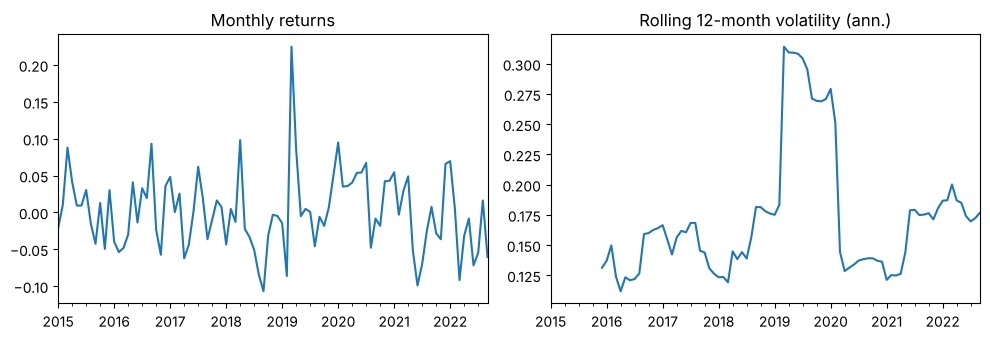

Annualised vol from daily  : 0.1907
Annualised vol from monthly: 0.1803 (close, but noisier)


In [17]:
rng = np.random.default_rng(0)
idx = pd.bdate_range("2015-01-01", periods=252 * 8)        # business days
daily_ret = pd.Series(rng.normal(0.0004, 0.012, len(idx)), index=idx, name="ret")

# Resample daily -> monthly (compound the simple returns)
monthly_ret = (1 + daily_ret).resample("ME").prod() - 1

# Rolling 12-month volatility (annualised)
roll_vol = monthly_ret.rolling(window=12).std() * np.sqrt(12)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
monthly_ret.plot(ax=ax[0], title="Monthly returns")
roll_vol.plot(ax=ax[1], title="Rolling 12-month volatility (ann.)")
plt.tight_layout(); plt.show()
print("Annualised vol from daily  :", round(np.sqrt(252) * daily_ret.std(), 4))
print("Annualised vol from monthly:", round(np.sqrt(12) * monthly_ret.std(), 4), "(close, but noisier)")

### A tiny out-of-sample loop (preview of Chapters 2–4)

This is the skeleton of every backtest in the course. Learn its structure: **estimate on the past window → choose weights → apply them to next period's returns.**

In [18]:
rng = np.random.default_rng(1)
T, N, T_est = 240, 3, 60
R = pd.DataFrame(rng.multivariate_normal(mu / 12, V / 12, size=T),
                 columns=["A1", "A2", "A3"])

oos = []
for t in range(T_est, T):
    window = R.iloc[t - T_est:t]                 # information up to t-1 only
    V_hat = window.cov().values
    w = np.linalg.solve(V_hat, np.ones(N))
    w = w / w.sum()                              # GMV weights
    oos.append(w @ R.iloc[t].values)             # return earned at t (out of sample)

oos = pd.Series(oos)
print(f"Out-of-sample GMV: mean {12*oos.mean():.4f}, vol {np.sqrt(12)*oos.std():.4f}, "
      f"Sharpe (excess of 0) {np.sqrt(12)*oos.mean()/oos.std():.3f}")

Out-of-sample GMV: mean 0.0145, vol 0.0892, Sharpe (excess of 0) 0.162


✍️ **Exam-ready: rolling-window backtest skeleton**
```python
oos = []
for t in range(T_est, T):
    window = R.iloc[t - T_est:t]
    w = np.linalg.solve(window.cov().values, np.ones(N)); w = w / w.sum()
    oos.append(w @ R.iloc[t].values)
```

## 7. Exercises

Try each one on paper first (exam conditions!), then type it and check. Solutions are hidden: click **"Solution"** to open them.

**Exercise 1.** Given `mu`, `V`, `rf = 0.02`, compute the weights of the **tangency portfolio** (the MV portfolio rescaled so that the risky weights sum to 1). What is its Sharpe ratio?

<details><summary><b>Solution</b></summary>

```python
ex = mu - rf * np.ones(len(mu))
w_tan = np.linalg.solve(V, ex)
w_tan = w_tan / w_tan.sum()
sharpe = (w_tan @ ex) / np.sqrt(w_tan @ V @ w_tan)
```
The tangency portfolio does not depend on γ: γ only decides how much you put in it versus the risk-free asset.
</details>

**Exercise 2.** You receive a tidy DataFrame `df` with columns `symbol, date, adjusted`. Write a chain that returns a **wide** DataFrame of monthly returns, with no missing values, ready for `.cov()`.

<details><summary><b>Solution</b></summary>

```python
ret_wide = (df
  .sort_values(["symbol", "date"])
  .assign(ret=lambda x: x.groupby("symbol")["adjusted"].pct_change())
  .pivot(index="date", columns="symbol", values="ret")
  .dropna())
V_hat = ret_wide.cov()
```
</details>

**Exercise 3.** Show numerically that, for $N=1$, the matrix formula gives $w_1=\frac{1}{\gamma}\frac{\mu-r_f}{\sigma^2}$.

<details><summary><b>Solution</b></summary>

```python
mu1, s1 = 0.08, 0.20
w_matrix = np.linalg.solve(np.array([[s1**2]]), np.array([mu1 - rf])) / gamma
w_scalar = (mu1 - rf) / (gamma * s1**2)
print(w_matrix, w_scalar)   # both 0.5
```
</details>

**Exercise 4.** In the rolling-window loop above, replace GMV with **1/N** weights and compare the out-of-sample Sharpe ratios. (DeMiguel, Garlappi and Uppal 2009 is the famous paper on this comparison; it comes back in Chapter 4.)

<details><summary><b>Solution</b></summary>

```python
oos_ew = [np.ones(N) / N @ R.iloc[t].values for t in range(T_est, T)]
oos_ew = pd.Series(oos_ew)
print(np.sqrt(12) * oos_ew.mean() / oos_ew.std())
```
</details>

In [19]:
# Space for your work: Exercise 1

In [20]:
# Space for your work: Exercise 2-4